Good start! Some comments for improvement:

    The dataset needs to be explained in the beginning of the EDA.
    Dropping duration makes sense, but should be explained
    The metrics for training should also be printed, to discuss overfitting etc.
    In this assignment when tuning; you should test each value for each hyper parameter multiple times (3-5) instead of using random state, and then take the average. This would make your results less likely to be random.
    I could not see any discussion regarding why your choice of main metric is f1.
    Since you are tuning based on f1, it would make sense to test a higher value for max depth since your results show the f1-score increasing when max depth is increased.
    Similarly for min samples split; since 20 gave the best f1-score, you should test a few more values around this number. Nice plot after tuning this! This shows what parameter value you should test more values close to:)
    Similarly for var smoothing
    The results should be discussed more in relation to the domain of the dataset

Except for my comments you did a solid job! Good structure, content and well commented. 

these comments from the previous, now the assignment:

an exploratory data analysis
data processing with multiple alternatives
automated hyperparameter tuning (ideally also of processing parameters/choices)

    You should tune at least three model parameters where possible. Groups of one can aim for at least two. Groups of three should aim for at least four.

evaluation using accuracy, precision, recall, and the f-measure
evaluation using confusion matrices and suitable plots 

The submission should be one or more Jupyter notebooks compressed into either a zip or tar.gz. You should take care to make the presentation well structured easy to read. Use markdown to document all relevant outputs.

THE COMMENTS FOR THIS SUBMISSION:


    Remember to remove my comments from the notebook before the final evaluation.

    You should deliver on time next time.

    Good that you have explained your dataset briefly, but it would be better if you explained each one of the features, for example in a list. This will show that you know exactly what everything is, and also make it easy to understand for me when evaluating your assignment.

    Make sure that all cells are run before delivery.

    You should explain why you chose as much as 40% of your data as test.

    You should analyze your results from cv, and consider adjusting the grid if needed based on your validation results. 

    You need to add advanced models, ANNs, analysis of results and conclusion.


Good start. There are several important things missing, especially the advanced models and ANNs that needs to be added before final evaluation.


In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sb 
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline 
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold,RepeatedStratifiedKFold
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV



In [2]:
dataset = pd.read_csv('../data/online_shoppers_intention.csv')
dataset.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


# DATA EXPLANATION:

Administration, Administrative_Duration, Informational, Informational_Duration, ProductRelated and Product Related_Duration. Each one represents the number of  different types of pages visited in a sesion and the total time of that session.

BounceRates, ExitRates and PageValues represents the metrics given in Google Analytics. Being BounceRates the percentage of people than enters and "bounce" back withouth doing another action, ExitRates is the calculations of all the pageviews of the page, and then the percent of those who were in the last session  and the PageValue is the average value that a page has to have for a visitor to visit it and then complete an e-commerce transaction.

SpecialDay feature shows if a page is visited in a holiday or a marked day such as Mother's Day, Valentine's day.

The next features are more easy to understand: Month, OperatingSystems, Browser, Region, TrafficTYpe, VisitorType, Weekend and Revenue. Some of these columns are anonymous so we cant really tell for example which OS is forn each number, or which region is which number, but that won't be a problem for the study of this dataset, we will only get a foggy output of some features.

This dataset consists of 12330 sessions of shopping. All of the data was collected within a 1 year period to avoid atypical data, such as holidays, special campaigns, etc.



# 1 EDA:

## 1.1 Data information



In [3]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

We don't have any null Values which is going to enrich our study and make our lifes easier because we don't have to deal with Nan Values.

In [4]:
dataset.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


### 1.2 Histograms

array([[<Axes: title={'center': 'Administrative'}>,
        <Axes: title={'center': 'Administrative_Duration'}>,
        <Axes: title={'center': 'Informational'}>,
        <Axes: title={'center': 'Informational_Duration'}>],
       [<Axes: title={'center': 'ProductRelated'}>,
        <Axes: title={'center': 'ProductRelated_Duration'}>,
        <Axes: title={'center': 'BounceRates'}>,
        <Axes: title={'center': 'ExitRates'}>],
       [<Axes: title={'center': 'PageValues'}>,
        <Axes: title={'center': 'SpecialDay'}>,
        <Axes: title={'center': 'OperatingSystems'}>,
        <Axes: title={'center': 'Browser'}>],
       [<Axes: title={'center': 'Region'}>,
        <Axes: title={'center': 'TrafficType'}>, <Axes: >, <Axes: >]],
      dtype=object)

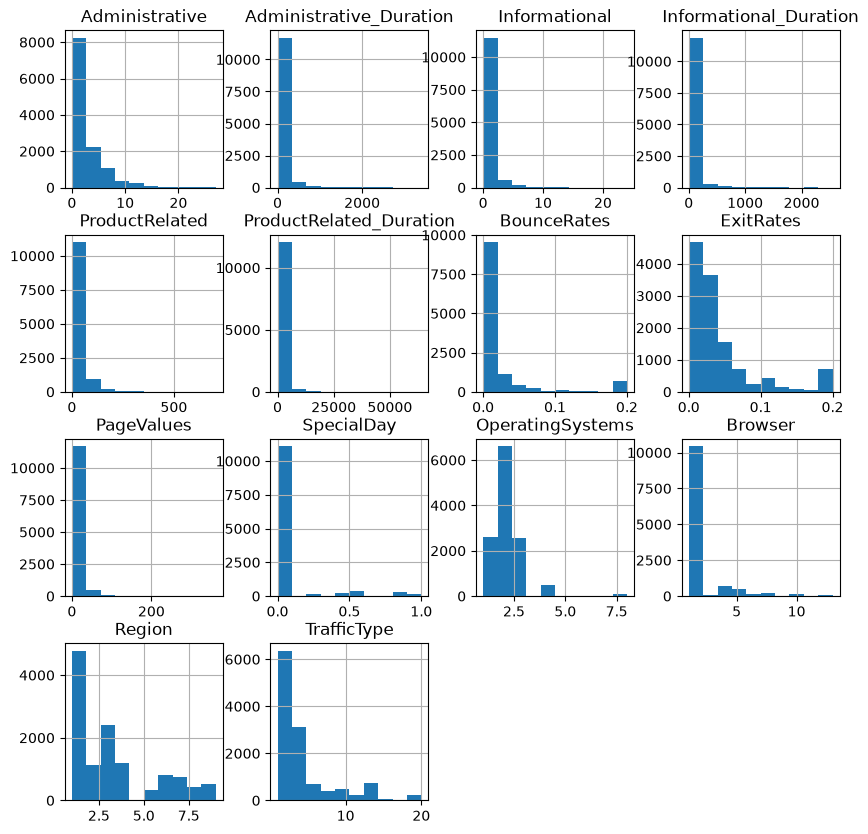

In [5]:
#We make our first EDA by using histograms


dataset.hist(figsize=(10,10))


<Axes: xlabel='VisitorType', ylabel='count'>

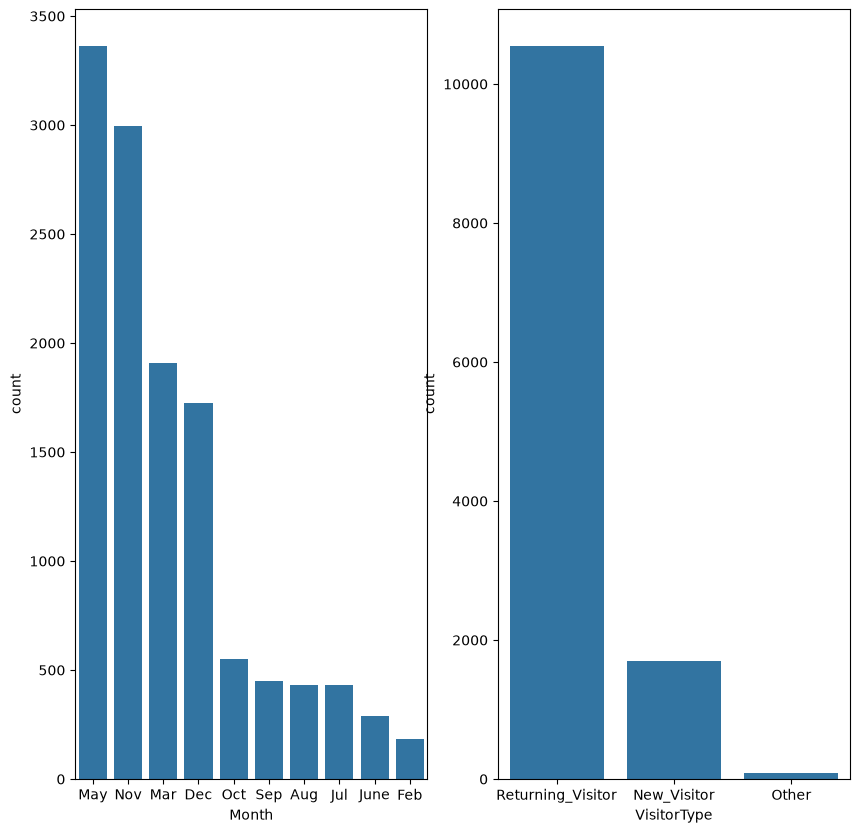

In [6]:
#For categorical data we can use distributions and look at the values

fig, axis= plt.subplots(1,2, figsize=(10,10))

sb.barplot(dataset['Month'].value_counts(), ax=axis[0])
sb.barplot(dataset['VisitorType'].value_counts(),ax=axis[1])

## 1.3  BarPlots Study:

As we can see of all the months studied we can see a pattern: November and December in a pair because the Christmas shopping before the gifts period.

May and Mar we could say that they are often visited in this period because they are packed with holidays and people use their free time for internet shopping.


### After this we can do a correlation analysis:

We have to drop all the features that are not numerical, that is to say, the last 2 features that we use in the BarPlots



In [7]:
correlation = dataset.corr(numeric_only=True)
correlation.style.background_gradient(cmap='managua')

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue
Administrative,1.000000,0.601583,0.376850,0.255848,0.431119,0.373939,-0.223563,-0.316483,0.098990,-0.094778,-0.006347,-0.025035,-0.005487,-0.033561,0.026417,0.138917
Administrative_Duration,0.601583,1.000000,0.302710,0.238031,0.289087,0.355422,-0.144170,-0.205798,0.067608,-0.073304,-0.007343,-0.015392,-0.005561,-0.014376,0.014990,0.093587
Informational,0.376850,0.302710,1.000000,0.618955,0.374164,0.387505,-0.116114,-0.163666,0.048632,-0.048219,-0.009527,-0.038235,-0.029169,-0.034491,0.035785,0.095200
Informational_Duration,0.255848,0.238031,0.618955,1.000000,0.280046,0.347364,-0.074067,-0.105276,0.030861,-0.030577,-0.009579,-0.019285,-0.027144,-0.024675,0.024078,0.070345
ProductRelated,0.431119,0.289087,0.374164,0.280046,1.000000,0.860927,-0.204578,-0.292526,0.056282,-0.023958,0.004290,-0.013146,-0.038122,-0.043064,0.016092,0.158538
ProductRelated_Duration,0.373939,0.355422,0.387505,0.347364,0.860927,1.000000,-0.184541,-0.251984,0.052823,-0.036380,0.002976,-0.007380,-0.033091,-0.036377,0.007311,0.152373
BounceRates,-0.223563,-0.144170,-0.116114,-0.074067,-0.204578,-0.184541,1.000000,0.913004,-0.119386,0.072702,0.023823,-0.015772,-0.006485,0.078286,-0.046514,-0.150673
ExitRates,-0.316483,-0.205798,-0.163666,-0.105276,-0.292526,-0.251984,0.913004,1.000000,-0.174498,0.102242,0.014567,-0.004442,-0.008907,0.078616,-0.062587,-0.207071
PageValues,0.098990,0.067608,0.048632,0.030861,0.056282,0.052823,-0.119386,-0.174498,1.000000,-0.063541,0.018508,0.045592,0.011315,0.012532,0.012002,0.492569
SpecialDay,-0.094778,-0.073304,-0.048219,-0.030577,-0.023958,-0.036380,0.072702,0.102242,-0.063541,1.000000,0.012652,0.003499,-0.016098,0.052301,-0.016767,-0.082305


### 1.4  Correlation conclusions:

As we can see the upper left body is Pretty tightly connecetd because every feature until BounceRates is interwinded with each other. But there is an interesting breakthrough that makes a lot of sense. We can see that Revenue and PageValue are pretty much connected with a whoping 0.4925 , that is translated in: if the page is valueable (pretty, efficient, intuitive) that is gonna make more sales.

### 1.5 Boxplot study

Administrative                Axes(0.125,0.786098;0.352273x0.0939024)
Administrative_Duration    Axes(0.547727,0.786098;0.352273x0.0939024)
Informational                 Axes(0.125,0.673415;0.352273x0.0939024)
Informational_Duration     Axes(0.547727,0.673415;0.352273x0.0939024)
ProductRelated                Axes(0.125,0.560732;0.352273x0.0939024)
ProductRelated_Duration    Axes(0.547727,0.560732;0.352273x0.0939024)
BounceRates                   Axes(0.125,0.448049;0.352273x0.0939024)
ExitRates                  Axes(0.547727,0.448049;0.352273x0.0939024)
PageValues                    Axes(0.125,0.335366;0.352273x0.0939024)
SpecialDay                 Axes(0.547727,0.335366;0.352273x0.0939024)
OperatingSystems              Axes(0.125,0.222683;0.352273x0.0939024)
Browser                    Axes(0.547727,0.222683;0.352273x0.0939024)
Region                            Axes(0.125,0.11;0.352273x0.0939024)
TrafficType                    Axes(0.547727,0.11;0.352273x0.0939024)
dtype: object

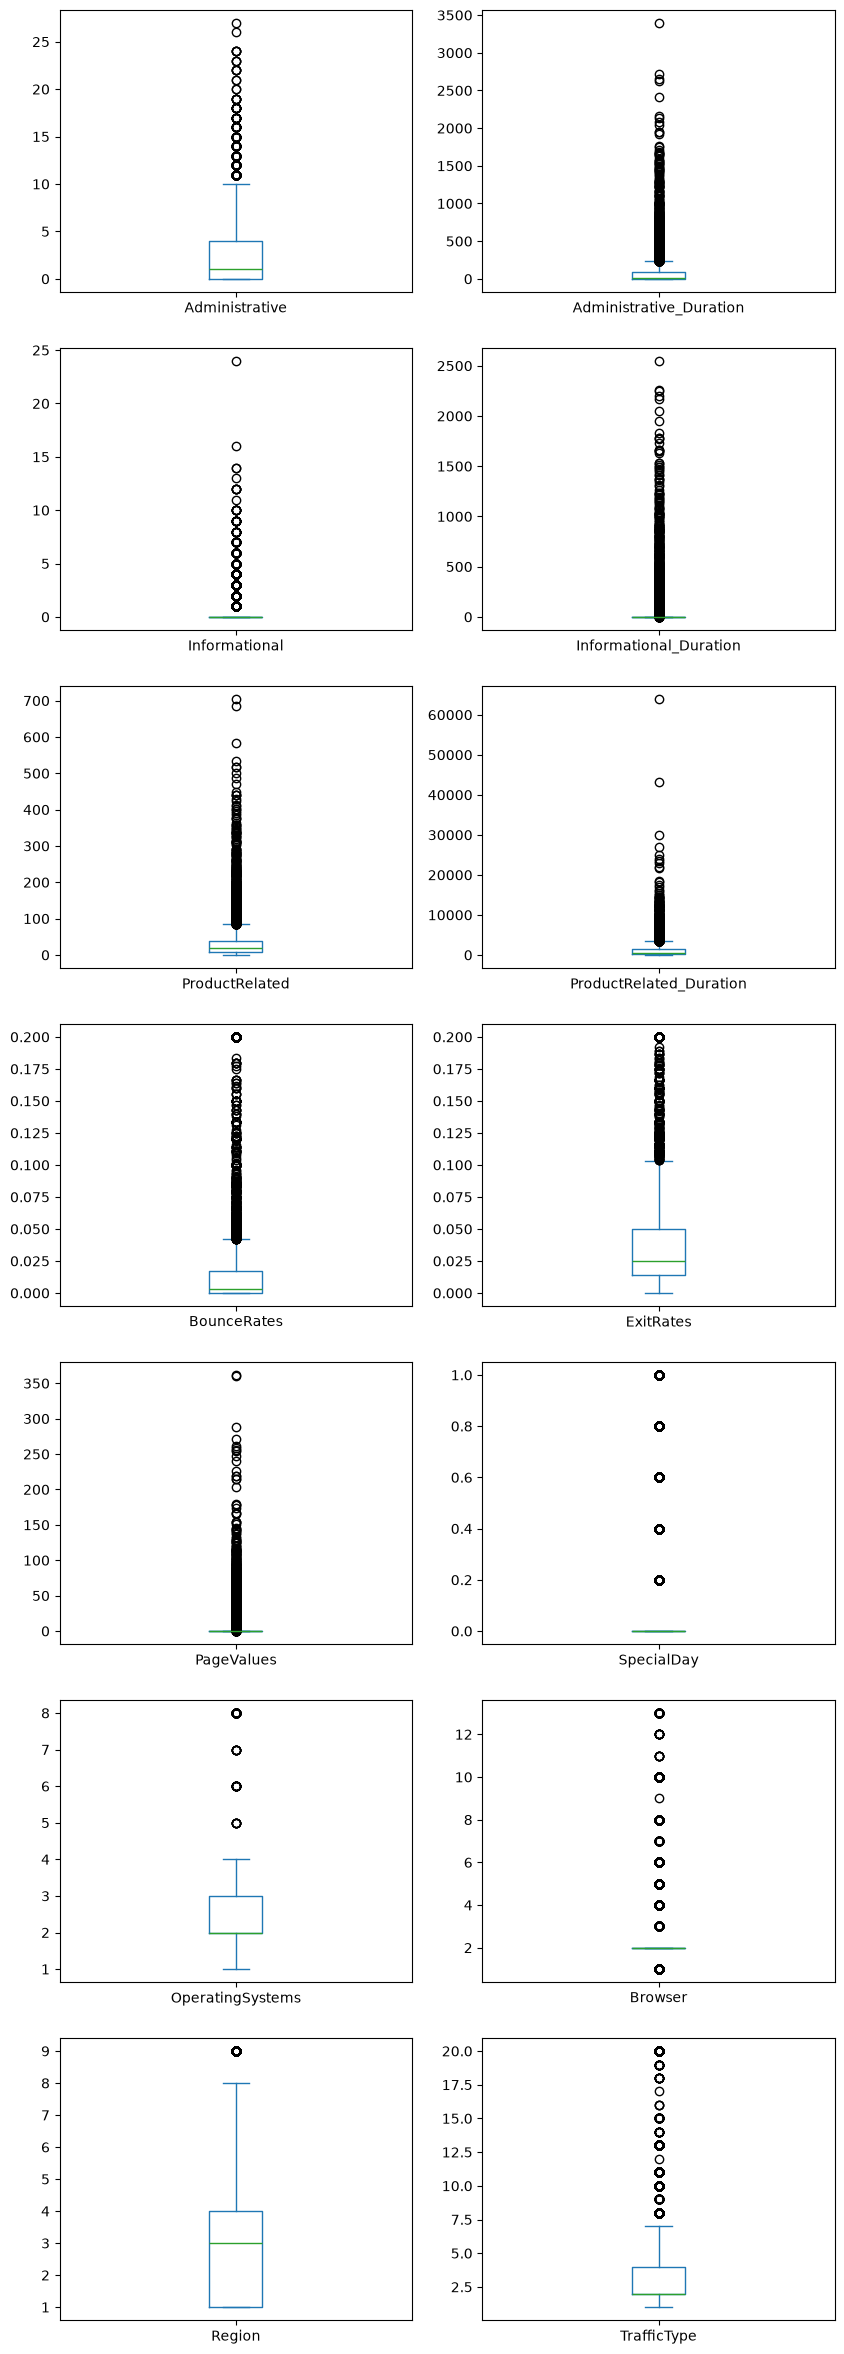

In [8]:
#Boxplots for the data to check atypical data:


cols=['Administrative','Administrative_Duration','Informational','Informational_Duration'
        ,'ProductRelated','ProductRelated_Duration','BounceRates','ExitRates'
            ,'PageValues','SpecialDay','OperatingSystems','Browser','Region','TrafficType'];


dataset[cols].plot(kind='box',subplots=True,sharey=False,figsize=(10,30),layout=(7,2),sharex=False)

### 1.6  Pairplot

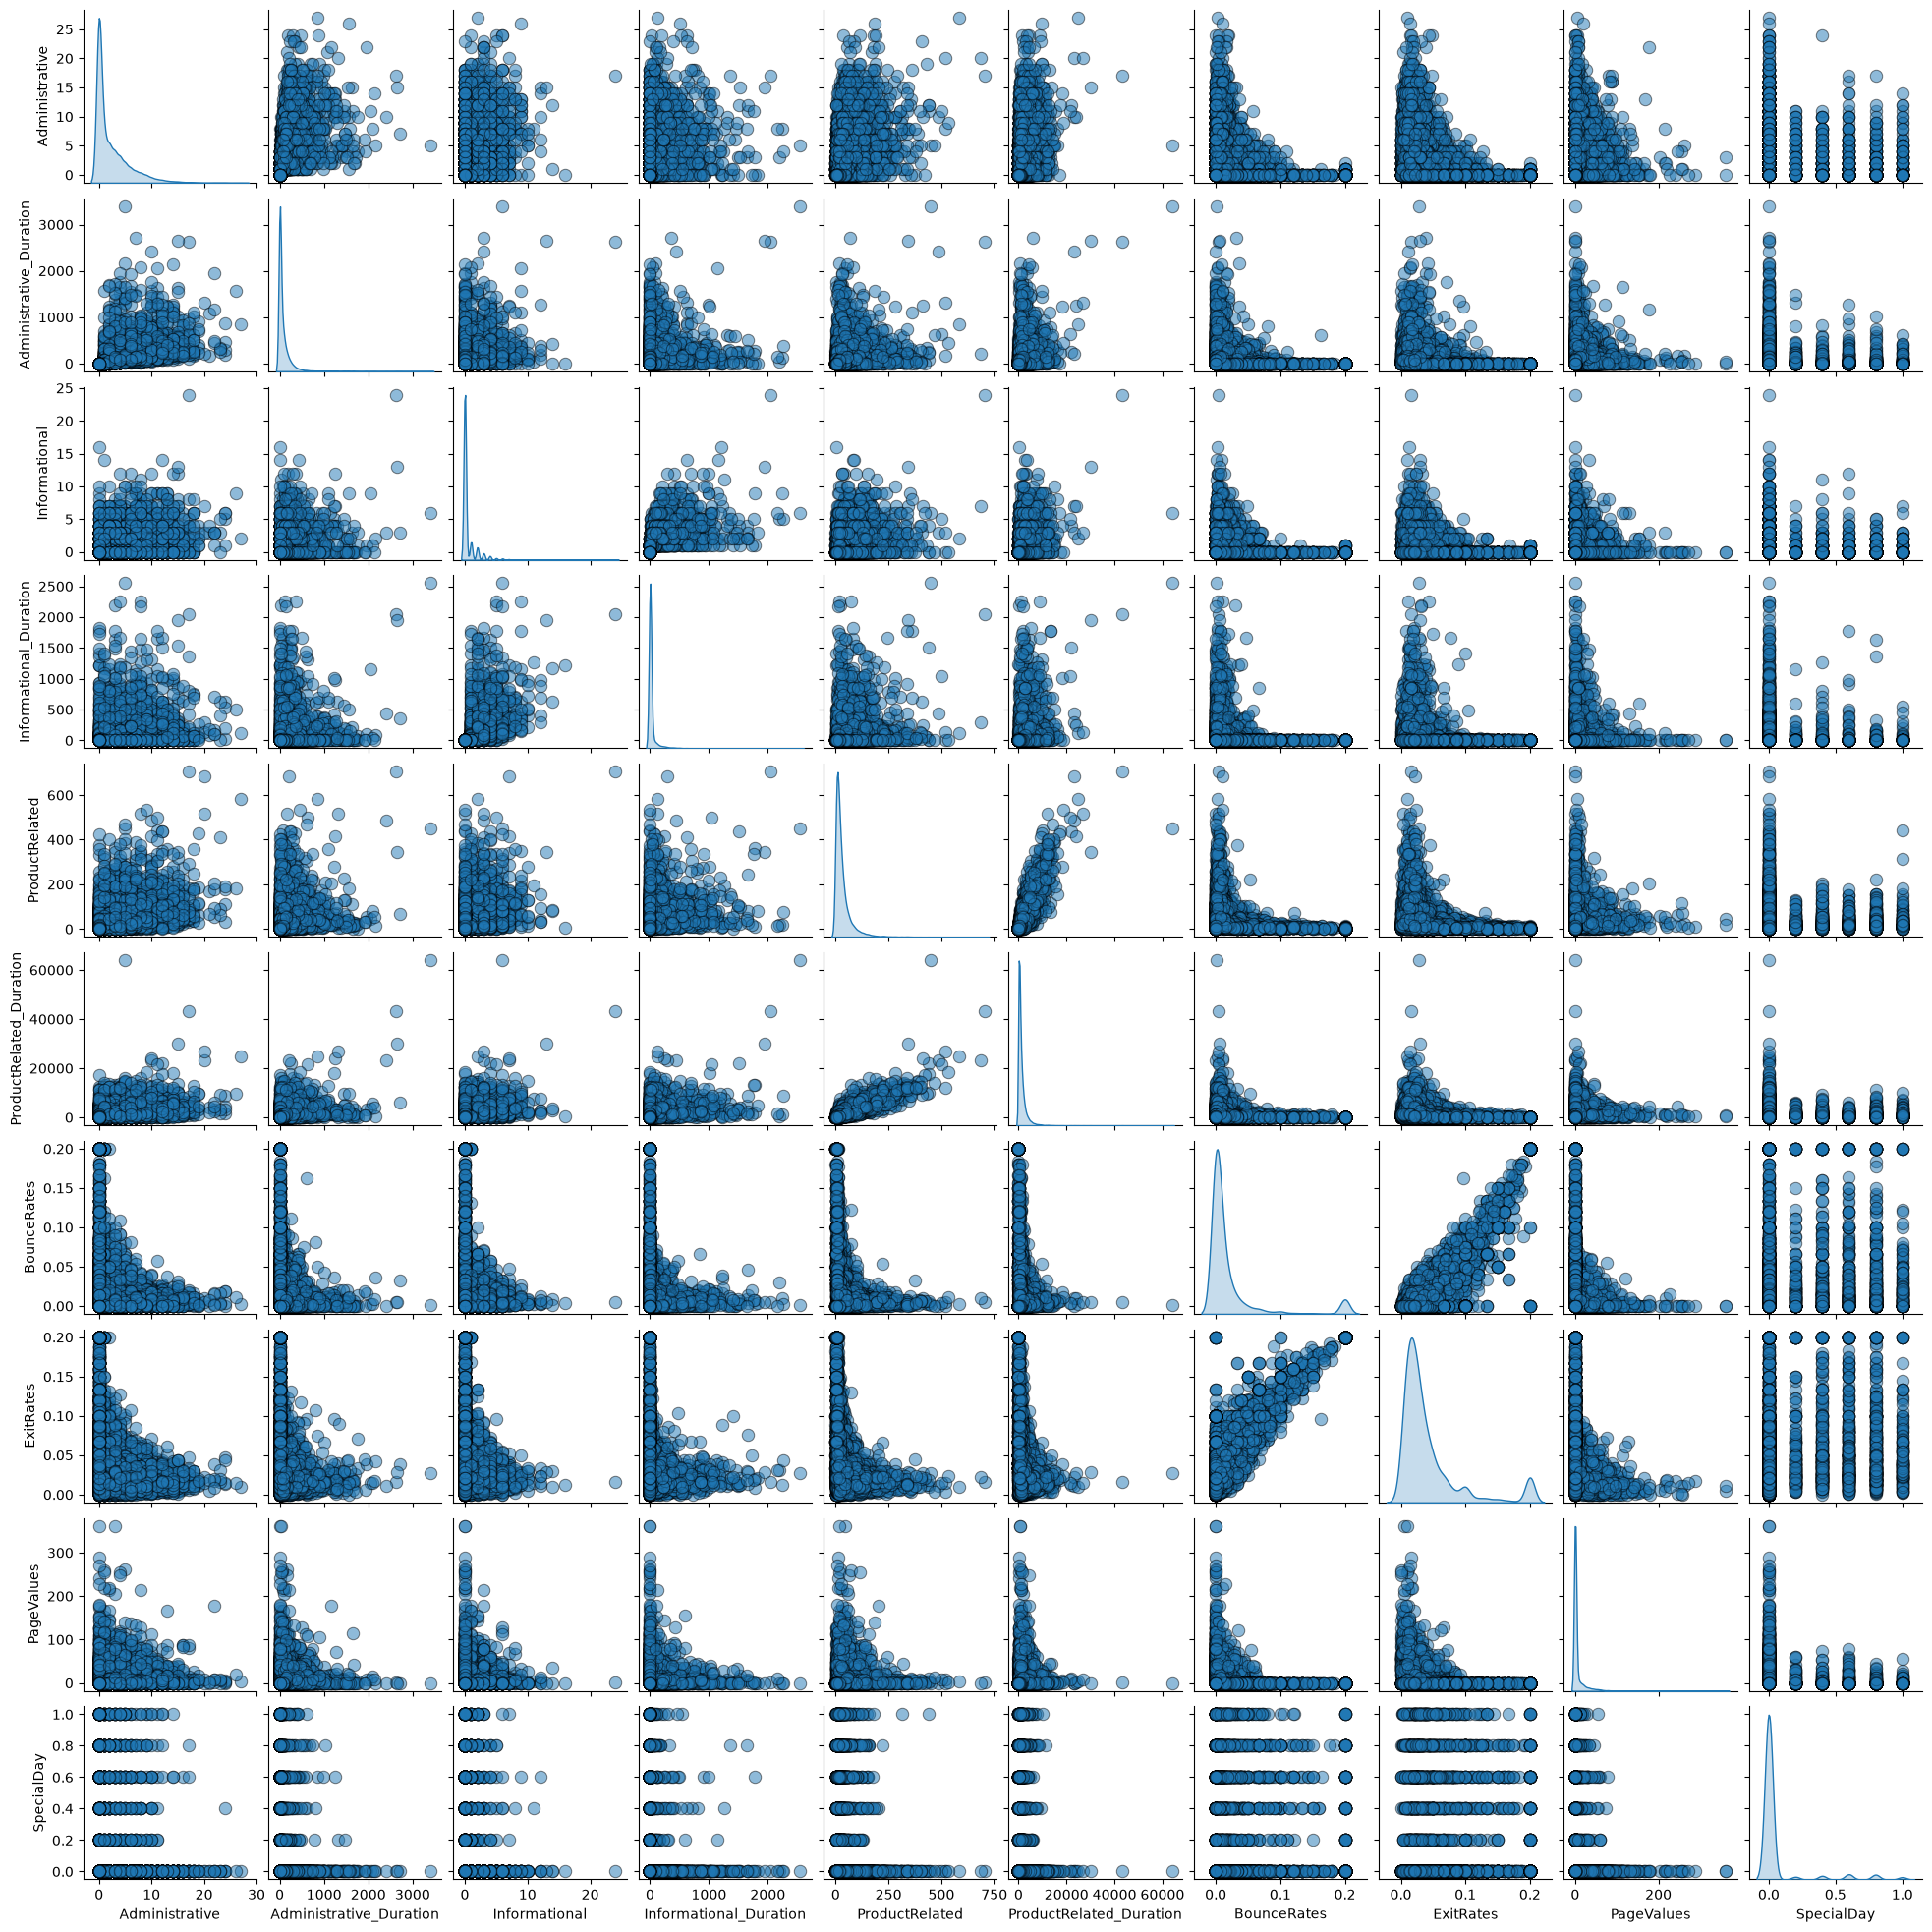

In [9]:
subset_features = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
sb.pairplot(dataset[subset_features], diag_kind='kde', plot_kws={'alpha':0.5, 's':80, 'edgecolor':'k'}, height=2)



# 2. Data Processing

#### 2.1 Target and feature preparation
The target `Revenue` is binary. `Revenue` and `Weekend` are converted from bool to int. The categorical features are listed separately, since they are encoded later in the pipeline.



In [10]:
dataset = dataset.drop_duplicates()

dataset['Revenue'] = dataset['Revenue'].astype(int)
dataset['Weekend'] = dataset['Weekend'].astype(int)

categorical_features = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
numerical_features = dataset.drop(categorical_features + ['Weekend', 'Revenue'], axis=1).columns
numerical_features_nopagevalues = numerical_features.drop('PageValues')

dataset.shape

(12205, 18)

#### 2.2 Stratified train/test split
We are gonna make a 70/30 split of the train data and test data. THis is gonna give us a good margin for the test, whi is gonna get roughly 600 , enough for a stable precision, recall and F1 estimation but leaving almost 8,500 . The test split is not used until the final evaluation.



In [11]:
global_random_state = 67

dataset_train, dataset_test = train_test_split(
    dataset, test_size=0.3, shuffle=True, stratify=dataset['Revenue'], random_state=global_random_state)

features_trainval = dataset_train.drop('Revenue', axis=1)
features_test = dataset_test.drop('Revenue', axis=1)
targets_trainval = dataset_train['Revenue']
targets_test = dataset_test['Revenue']

print(features_trainval.shape)
print(features_test.shape)
#To check we have good values, this test should be around 0.15
print(targets_trainval.mean(), targets_test.mean())

(8543, 17)
(3662, 17)
0.1563853447266768 0.156198798470781


#### 2.3 Category lists for the encoders
All category values are stored so the encoders in the pipeline do not fail when a cross-validation fold is missing a rare value.

In [12]:

categories = [sorted(dataset[c].unique()) for c in categorical_features]

preprocess = ColumnTransformer([
    ('categorical', OneHotEncoder(categories=categories), categorical_features),
    ('numerical', 'passthrough', numerical_features)],
    remainder='passthrough')

preprocess_params = {
    'preprocess__categorical': [OneHotEncoder(categories=categories), TargetEncoder(categories=categories)],
    'preprocess__numerical': ['passthrough', StandardScaler(), MinMaxScaler()]
}

imbalance_params = {'estimator__class_weight': [None, 'balanced']}

# 3. Modeling


### Targets

We are gonna use the `Revenue as the target`. Because Revenue and  Weekend are boolean, we need to changes them from true/false to 1/0, to an int.

In [13]:
#We make the target translating from boolean to int:

target = dataset['Revenue'].astype(int)

#We do the translation with the weekend:

dataset['Weekend']=dataset['Weekend'].astype(int)

#Now we drop the target from the dataset

dataset= dataset.drop(columns=['Revenue'])

#We double check that we are dropping the revenue from the dataset

dataset.info()



<class 'pandas.DataFrame'>
Index: 12205 entries, 0 to 12329
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12205 non-null  int64  
 1   Administrative_Duration  12205 non-null  float64
 2   Informational            12205 non-null  int64  
 3   Informational_Duration   12205 non-null  float64
 4   ProductRelated           12205 non-null  int64  
 5   ProductRelated_Duration  12205 non-null  float64
 6   BounceRates              12205 non-null  float64
 7   ExitRates                12205 non-null  float64
 8   PageValues               12205 non-null  float64
 9   SpecialDay               12205 non-null  float64
 10  Month                    12205 non-null  str    
 11  OperatingSystems         12205 non-null  int64  
 12  Browser                  12205 non-null  int64  
 13  Region                   12205 non-null  int64  
 14  TrafficType              12205 non-nul

## Splitting between numerical and categorical data

We know that there is numerical data that doesnt have a real numerical value, is just a code. We dont want to feed to machines number that cannot be used as 4 > 2, which could mean 4 being Spain and 2 being Norway.

Also because of the scales of the number, we have features ranging from 0 to thousands and others from 0 to 1

In the other hand, we have the Weekend feature which is gonna have a special treatment as changing the scale is not gonna hel us in any way, so we are just going to pass it down withouth any changes

In [14]:
numeric=['Administrative','Administrative_Duration','Informational','Informational_Duration'
        ,'ProductRelated','ProductRelated_Duration','BounceRates','ExitRates'
            ,'PageValues','SpecialDay'];
categorical=['Month','VisitorType','OperatingSystems','Browser','Region','TrafficType']





## Pre-processing

In [15]:
pre = ColumnTransformer(transformers=[ 
                                        ('num', StandardScaler(), numeric),
                                        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical )],
                                        remainder='passthrough')

In [16]:
#Cross validation will be fixed another time:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=13)

print("Cross-validation setup:", cv)
print("Number of folds:", cv.get_n_splits())

Cross-validation setup: StratifiedKFold(n_splits=5, random_state=13, shuffle=True)
Number of folds: 5


#### Model 1: Decision Tree (default + tuned)

In [17]:
#tuning


dt = Pipeline([
    ('preprocess', clone(preprocess)),
    ('model', DecisionTreeClassifier(random_state=67))
])

dt_params = {
    'model__max_depth': [None, 5, 10, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 5],
    'model__criterion': ['gini', 'entropy'],
    'preprocess__categorical__min_frequency': [None, 10, 50]
}

dt_grid = GridSearchCV(
    dt,
    dt_params,
    cv=RepeatedStratifiedKFold(n_splits=3,n_repeats=3, random_state=67),
    scoring='f1',
    n_jobs=-1
)

dt_grid.fit(features_trainval, targets_trainval)

dt_best = dt_grid.best_estimator_

print("Best parameters:", dt_grid.best_params_)
print("Best CV F1-score:", dt_grid.best_score_)

Best parameters: {'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__min_samples_split': 10, 'preprocess__categorical__min_frequency': 50}
Best CV F1-score: 0.6381941580952012


In [18]:
dt_tuned_pred = dt_best.predict(features_test)

print("Decision Tree – Tuned")
print("Accuracy:", accuracy_score(targets_test, dt_tuned_pred))
print("F1-score:", f1_score(targets_test, dt_tuned_pred))

Decision Tree – Tuned
Accuracy: 0.8965046422719826
F1-score: 0.633107454017425


#### Model 2: Naive Bayes (default + tuned)

In [19]:
pipe_nb = Pipeline([('prep', pre), ('model', GaussianNB())])

pipe_nb.fit(features_trainval, targets_trainval)

targets_pred = pipe_nb.predict(dataset_test)

cm_nb = confusion_matrix(targets_test, targets_pred)

print(classification_report(targets_test, targets_pred))

              precision    recall  f1-score   support

           0       0.99      0.16      0.27      3090
           1       0.18      0.99      0.30       572

    accuracy                           0.29      3662
   macro avg       0.58      0.57      0.29      3662
weighted avg       0.86      0.29      0.28      3662



In [20]:
#We are gonna add two processing options:

param_grid_nb = {
    #Model parameters (we can only tune this)
    'model__var_smoothing': np.logspace(-9,0,10),
    #Processing choice(WHich scaler)
    'prep__num': [StandardScaler(), MinMaxScaler(),RobustScaler(),'passthrough'],
    #Group rare categories together or none
    'prep__cat__min_frequency': [None, 10, 50]
}

grid_nb = GridSearchCV(
    estimator = pipe_nb,
    param_grid= param_grid_nb,
    scoring='f1',
    #TO ensure that we test a sufficient amount we use the repeated stratified kfold so we test 15 times
    cv= RepeatedStratifiedKFold(n_splits=3,n_repeats=3, random_state=67),
    n_jobs=-1,
    return_train_score=True
)


grid_nb.fit(features_trainval, targets_trainval)

print(grid_nb.best_params_)
print(grid_nb.best_score_)       

targets_pred_nb = grid_nb.best_estimator_.predict(dataset_test)
print(classification_report(targets_test, targets_pred_nb))
cm_nb_tuned = confusion_matrix(targets_test, targets_pred_nb)


{'model__var_smoothing': np.float64(1e-05), 'prep__cat__min_frequency': 50, 'prep__num': RobustScaler()}
0.5446508769287496
              precision    recall  f1-score   support

           0       0.93      0.87      0.90      3090
           1       0.48      0.62      0.54       572

    accuracy                           0.83      3662
   macro avg       0.70      0.75      0.72      3662
weighted avg       0.86      0.83      0.84      3662



#### Model 3: SGD/Logistic (default + tuned)

In [21]:

pipe_sgd = Pipeline([('prep', pre ), ('model', SGDClassifier(max_iter=1000))])

param_grid_sgd = {
    #model parameters
    'model__loss': ['hinge', 'log_loss', 'modified_huber'],
    'model__alpha': np.logspace(-6, -1, 6),
    'model__penalty': ['l2','l1', 'elasticnet'],
    'model__class_weight': [None, 'balanced'] ,
    #processing choices
    'prep__num': [StandardScaler(), MinMaxScaler(),RobustScaler()],
}

grid_sgd = GridSearchCV(
    estimator = pipe_sgd,
    param_grid= param_grid_sgd,
    scoring='f1',
    cv= RepeatedStratifiedKFold(n_splits=3, n_repeats=3, random_state=67),
    n_jobs=-1,
    return_train_score=True,
)

grid_sgd.fit(features_trainval, targets_trainval)

print(grid_sgd.best_params_)
print(grid_sgd.best_score_)

target_pred_sgd = grid_sgd.best_estimator_.predict(features_test)
print(classification_report(targets_test, target_pred_sgd))



/home/tibu/Documents/UNI/pml/lib/python3.13/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/tibu/Documents/UNI/pml/lib/python3.13/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/tibu/Documents/UNI/pml/lib/python3.13/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/tibu/Documents/UNI/pml/lib/python3.13/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


{'model__alpha': np.float64(0.001), 'model__class_weight': 'balanced', 'model__loss': 'modified_huber', 'model__penalty': 'l1', 'prep__num': MinMaxScaler()}
0.6618933383749909
              precision    recall  f1-score   support

           0       0.95      0.89      0.92      3090
           1       0.57      0.77      0.65       572

    accuracy                           0.87      3662
   macro avg       0.76      0.83      0.79      3662
weighted avg       0.89      0.87      0.88      3662



## Advanced models

Lets create variables to save the results for a later evaluation:

In [22]:
models = {}

models['NB'] = grid_nb.best_estimator_
models['SGD'] = grid_sgd.best_estimator_
models['DT'] = dt_best

### Model 4: Random Forest

In [23]:



pipe_rf = Pipeline([('prep', pre), ('model', RandomForestClassifier())])

param_grid_rf = {
    'model__n_estimators' : [75, 125, 200, 500],
    'model__max_depth' : [None, 5, 10, 20, 35],
    'model__min_samples_leaf' : [1, 2, 5, 8, 12],
    'model__max_features' : ['sqrt', 'log2', 0.5],
    'model__class_weight' : [None, 'balanced'],
    'prep__cat__min_frequency' : [None, 10, 25, 50],
}

#Because we have more than 200 combinations the grid is gonna be very slow,
#so for the search we are gonna use a randomized one:

search_rf = RandomizedSearchCV(
    estimator = pipe_rf,
    param_distributions = param_grid_rf,
    n_iter = 30,
    scoring = 'f1',
    cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=3, random_state=67),
    n_jobs=-1,
    return_train_score=True,
)

search_rf.fit(features_trainval, targets_trainval)


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [None, 5, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",RepeatedStrat...ndom_state=67)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimato

In [24]:
print(search_rf.best_params_)
print(search_rf.best_score_)

best_rf= search_rf.best_estimator_

#We test the evaluation

train_pred= best_rf.predict(features_trainval)
print("TRAIN: \t")
print(classification_report(targets_trainval, train_pred))

#Training

test_pred = best_rf.predict(features_test)
print("\n TEST: \t")
print(classification_report(targets_test, test_pred))

models['RF']= best_rf



{'prep__cat__min_frequency': 10, 'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 35, 'model__class_weight': 'balanced'}
0.6755528215919387
TRAIN: 	
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7207
           1       0.99      1.00      1.00      1336

    accuracy                           1.00      8543
   macro avg       1.00      1.00      1.00      8543
weighted avg       1.00      1.00      1.00      8543


 TEST: 	
              precision    recall  f1-score   support

           0       0.95      0.92      0.93      3090
           1       0.63      0.74      0.68       572

    accuracy                           0.89      3662
   macro avg       0.79      0.83      0.81      3662
weighted avg       0.90      0.89      0.89      3662



### Model 5:ANN

In [25]:
pipeline_mlp = Pipeline([('prep', pre), ('model', MLPClassifier(max_iter=500,early_stopping=True))])

param_grid_mlp = {
    'model__hidden_layer_sizes' : [(32,), (64,), (64,32), (128,64)],
    'model__activation' : ['relu', 'tanh'],
    'model__alpha' : np.logspace(-5,-1, 5),
    'model__learning_rate_init' : [0.0005, 0.001, 0.005, 0.01],
    'prep__num' : [StandardScaler(),MinMaxScaler(),RobustScaler()],
    'prep__cat__min_frequency' : [None, 10, 30, 50],
}

search_mlp = RandomizedSearchCV(
    estimator = pipeline_mlp,
    param_distributions = param_grid_mlp,
    n_iter = 20,
    scoring = 'f1',
    cv = RepeatedStratifiedKFold(n_splits= 3, n_repeats=3, random_state=67),
    n_jobs = -1,
    return_train_score = True,
)
search_mlp.fit(features_trainval, targets_trainval)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...x_iter=500))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__activation': ['relu', 'tanh'], 'model__alpha': array([1.e-05...e-02, 1.e-01]), 'model__hidden_layer_sizes': [(32,), (64,), ...], 'model__learning_rate_init': [0.0005, 0.001, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",RepeatedStrat...ndom_state=67)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatca

In [26]:
#Now the results

print(search_mlp.best_params_,search_mlp.best_score_)

best_mlp = search_mlp.best_estimator_

train_pred= best_mlp.predict(features_trainval)
print("TRAIN: \t")
print(classification_report(targets_trainval, train_pred))

#Training

test_pred = best_mlp.predict(features_test)
print("\n TEST: \t")
print(classification_report(targets_test, test_pred))

models['MLP']= best_mlp




{'prep__num': StandardScaler(), 'prep__cat__min_frequency': None, 'model__learning_rate_init': 0.001, 'model__hidden_layer_sizes': (128, 64), 'model__alpha': np.float64(0.01), 'model__activation': 'tanh'} 0.6243915599628609
TRAIN: 	
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      7207
           1       0.78      0.61      0.69      1336

    accuracy                           0.91      8543
   macro avg       0.85      0.79      0.82      8543
weighted avg       0.91      0.91      0.91      8543


 TEST: 	
              precision    recall  f1-score   support

           0       0.92      0.95      0.94      3090
           1       0.69      0.58      0.63       572

    accuracy                           0.89      3662
   macro avg       0.81      0.76      0.78      3662
weighted avg       0.89      0.89      0.89      3662



### Model 6: Histogram Gradient

In [27]:
#We follow the same structure as the forest tree
pipe_hgb = Pipeline([('prep', pre), ('model', HistGradientBoostingClassifier())])

param_grid_hgb = {
    'model__learning_rate' : [0.01, 0.03, 0.05, 0.1, 0.2],
    'model__max_depth' : [None, 3, 5, 8],
    'model__max_iter' : [100, 200, 400],
    'model__min_samples_leaf' : [10, 20, 40, 80],
    #IM gonna use the regularization as a way to fight overfitting,
    #penalizing large leafs.
    'model__l2_regularization' : [0, 0.1, 1, 5, 10],
    'model__class_weight' : [None, 'balanced'],
    'prep__cat__min_frequency' : [None, 10, 30, 50]
}

search_hgb = RandomizedSearchCV(
    estimator= pipe_hgb,
    param_distributions = param_grid_hgb,
    n_iter = 30,
    scoring = 'f1',
    cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=3, random_state=67),
    n_jobs=-1,
    return_train_score=True,
)

search_hgb.fit(features_trainval, targets_trainval)




,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__class_weight': [None, 'balanced'], 'model__l2_regularization': [0, 0.1, ...], 'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [None, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",RepeatedStrat...ndom_state=67)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimato

In [28]:
#And now the results

print(search_hgb.best_params_)
print(search_hgb.best_score_)

best_hgb= search_hgb.best_estimator_


train_pred= best_hgb.predict(features_trainval)
print("TRAIN: \t")
print(classification_report(targets_trainval, train_pred))

#Training

test_pred = best_hgb.predict(features_test)
print("\n TEST: \t")
print(classification_report(targets_test, test_pred))

models['HGB']= best_hgb




{'prep__cat__min_frequency': None, 'model__min_samples_leaf': 10, 'model__max_iter': 400, 'model__max_depth': None, 'model__learning_rate': 0.01, 'model__l2_regularization': 1, 'model__class_weight': 'balanced'}
0.6677257837364169
TRAIN: 	
              precision    recall  f1-score   support

           0       0.98      0.89      0.93      7207
           1       0.61      0.92      0.73      1336

    accuracy                           0.89      8543
   macro avg       0.79      0.90      0.83      8543
weighted avg       0.92      0.89      0.90      8543


 TEST: 	
              precision    recall  f1-score   support

           0       0.96      0.87      0.92      3090
           1       0.54      0.82      0.65       572

    accuracy                           0.86      3662
   macro avg       0.75      0.84      0.78      3662
weighted avg       0.90      0.86      0.87      3662



## Model 6: SVC

In [29]:
pipe_svc = Pipeline([('prep', pre), ('model', SVC())])

param_grid_svc = {
    'model__C': [0.1,0.5,1,5,10],
    'model__gamma': ['scale', 0.003, 0.01, 0.05, 0.1],
    'model__class_weight': [None, 'balanced'],
    'prep__num': [StandardScaler(), MinMaxScaler(),RobustScaler()],
    'prep__cat__min_frequency': [None, 5, 10, 25, 50],
}

search_svc = RandomizedSearchCV(
    estimator = pipe_svc,
    param_distributions=param_grid_svc,
    n_iter= 15,
    scoring = 'f1',
    cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=3,random_state=67),
    n_jobs=-1,
    return_train_score=True,
)

search_svc.fit(features_trainval, targets_trainval)



,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...del', SVC())])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__C': [0.1, 0.5, ...], 'model__class_weight': [None, 'balanced'], 'model__gamma': ['scale', 0.003, ...], 'prep__cat__min_frequency': [None, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",RepeatedStrat...ndom_state=67)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and

In [30]:
#And now the results

print(search_svc.best_params_)
print(search_svc.best_score_)

best_svc= search_svc.best_estimator_


train_pred= best_svc.predict(features_trainval)
print("TRAIN: \t")
print(classification_report(targets_trainval, train_pred))

#Training

test_pred = best_svc.predict(features_test)
print("\n TEST: \t")
print(classification_report(targets_test, test_pred))

models['SVC']= best_svc

{'prep__num': RobustScaler(), 'prep__cat__min_frequency': 10, 'model__gamma': 'scale', 'model__class_weight': 'balanced', 'model__C': 0.5}
0.6178743007286636
TRAIN: 	
              precision    recall  f1-score   support

           0       0.95      0.89      0.92      7207
           1       0.55      0.73      0.62      1336

    accuracy                           0.86      8543
   macro avg       0.75      0.81      0.77      8543
weighted avg       0.88      0.86      0.87      8543


 TEST: 	
              precision    recall  f1-score   support

           0       0.94      0.88      0.91      3090
           1       0.52      0.70      0.59       572

    accuracy                           0.85      3662
   macro avg       0.73      0.79      0.75      3662
weighted avg       0.87      0.85      0.86      3662



# 4. Evaluation
####  Accuracy, precision, recall, F1 for all 3 models

In [31]:
rows = []

#for name, model in models.items():
#    print(name, 'Revenue' in model.feature_names_in_)

#print('Revenue'in features_trainval.columns)
#print('Revenue' in features_test.columns)
#print(features_trainval.shape, features_test.shape)

for name, model in models.items():
    pred_test = model.predict(features_test)
    pred_train = model.predict(features_trainval)
    rows.append({
        'model': name,
        'accuracy': accuracy_score(targets_test,pred_test),
        'precision': precision_score(targets_test, pred_test),
        'recall': recall_score(targets_test, pred_test),
        'f1': f1_score(targets_test,pred_test),
        'f1_train': f1_score(targets_trainval, pred_train),
    })

summary = pd.DataFrame(rows).set_index('model')
summary.sort_values('f1', ascending=False)

,accuracy,precision,recall,f1,f1_train
model,,,,,
RF,0.891589,0.630792,0.737762,0.680097,0.997015
SGD,0.872201,0.566667,0.772727,0.653846,0.669440
HGB,0.863736,0.542393,0.816434,0.651779,0.730357
DT,0.896505,0.709328,0.571678,0.633107,0.683703
MLP,0.893774,0.691824,0.576923,0.629171,0.685595
SVC,0.850355,0.515504,0.697552,0.592868,0.623477
NB,0.834517,0.477089,0.618881,0.538813,0.543055


## Results of the models

`ẀRONG EVERYTHING REWRITE IT LATER`We can see that NB is the worst model of all. Also we can check with the very big gap between the f1_train and the f1 in the testing that the RF has a lot of overfitting. SO the best options are the HGB/SGF/DT/MLP. Because the difference in the f1 values are not big we really can't say one is better than the other. 




#### Plots 
##### Confusion Matrix

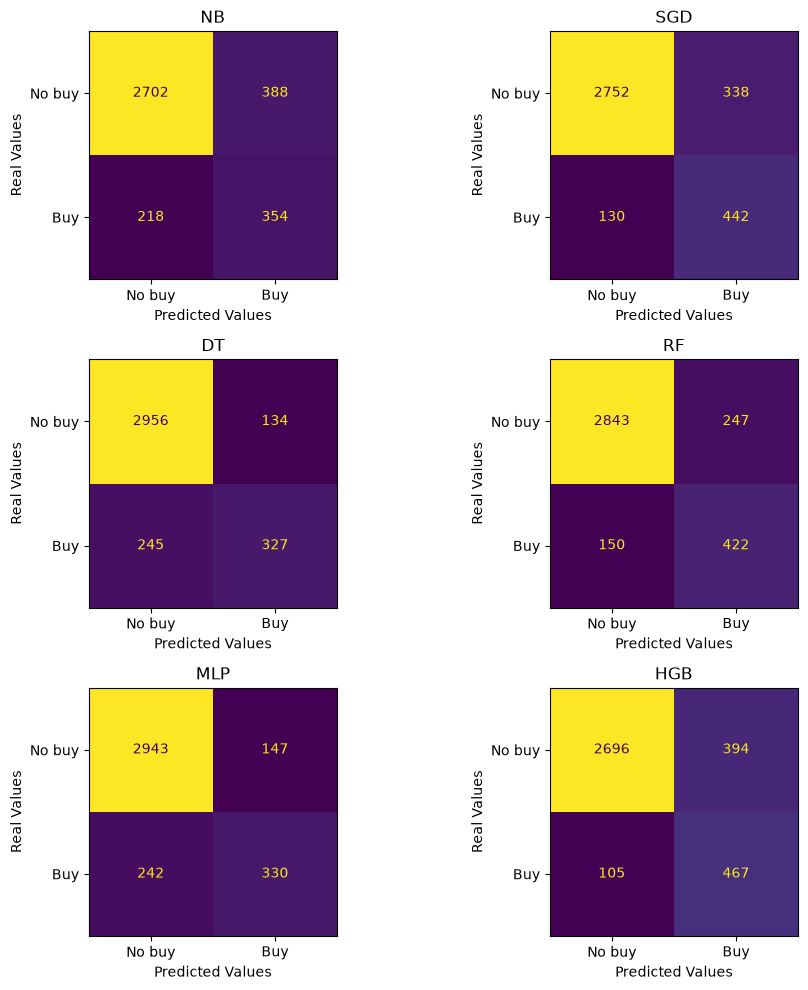

In [32]:
fig, axis = plt.subplots(3, 2, figsize=(10 ,10))
for ax, (name, model) in zip(axis.ravel(), models.items()):
    pred = model.predict(features_test)
    ConfusionMatrixDisplay.from_predictions(
        y_true=targets_test, y_pred=pred, display_labels=['No buy', 'Buy'],
        ax=ax, colorbar=False,
        )
    ax.set_title(name)
    ax.set_xlabel('Predicted Values')
    ax.set_ylabel('Real Values')
plt.tight_layout()
plt.show()

### Refine HGB model

After seeing that we are going to choose the HGB model, lets adjust the grid

['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_prep__cat__min_frequency', 'param_model__min_samples_leaf', 'param_model__max_iter', 'param_model__max_depth', 'param_model__learning_rate', 'param_model__l2_regularization', 'param_model__class_weight', 'params', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score', 'split4_test_score', 'split5_test_score', 'split6_test_score', 'split7_test_score', 'split8_test_score', 'mean_test_score', 'std_test_score', 'rank_test_score', 'split0_train_score', 'split1_train_score', 'split2_train_score', 'split3_train_score', 'split4_train_score', 'split5_train_score', 'split6_train_score', 'split7_train_score', 'split8_train_score', 'mean_train_score', 'std_train_score']


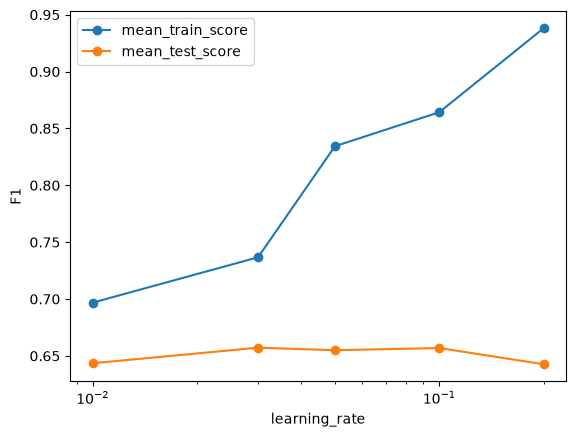

In [40]:
cv = pd.DataFrame(search_hgb.cv_results_)
print(cv.columns.tolist())

gr = cv.groupby('param_model__learning_rate')[['mean_train_score','mean_test_score']].mean()

gr.plot(marker='o', logx=True)

plt.xlabel('learning_rate'); 
plt.ylabel('F1') 
plt.show()

We can see a very clear turning oint on the learning rate, above 0.05 the train score gets a huge improvement while the test score gets stagnant. This shows clear signs of overfitting and the last value we can see that the ovetfitting ga makes the test score get even lower. The best values then are between 0.03 and 0.05

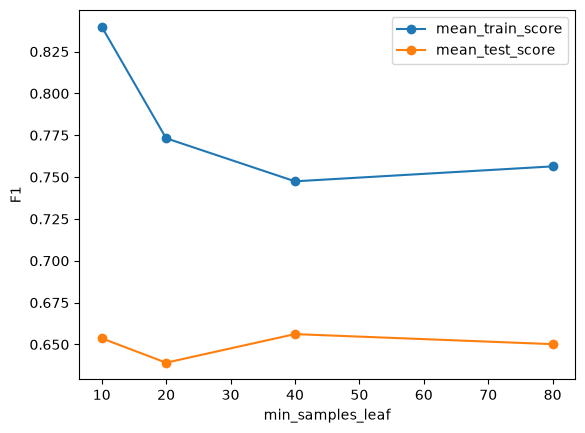

In [41]:
gr = cv.groupby('param_model__min_samples_leaf')[['mean_train_score','mean_test_score']].mean()

gr.plot(marker='o')

plt.xlabel('min_samples_leaf'); 
plt.ylabel('F1') 
plt.show()

so

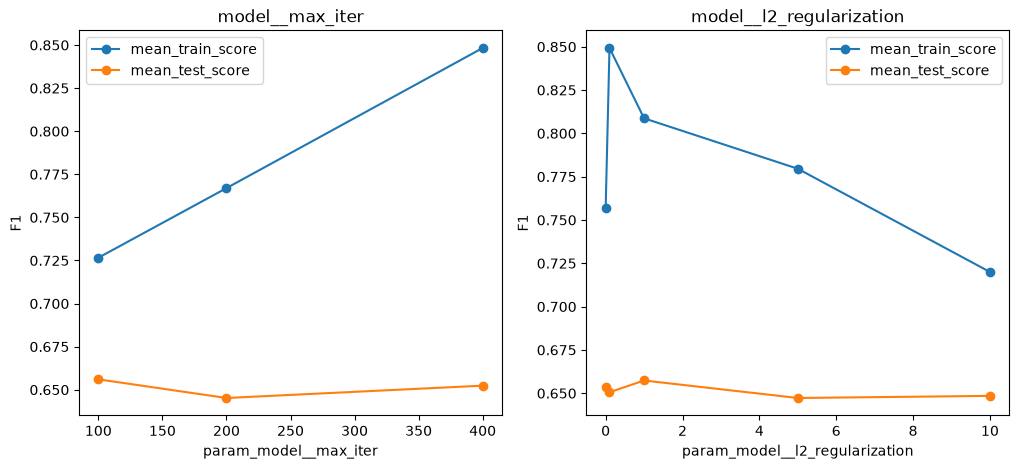

In [42]:
fig, axis = plt.subplots(1,2, figsize=(12,5))

for ax, p in zip(axis, ['model__max_iter', 'model__l2_regularization']):
    col = 'param_' + p
    gr = cv.groupby(col)[['mean_train_score','mean_test_score']].mean()
    gr.index = gr.index.astype(float)
    gr = gr.sort_index()
    gr.plot(ax=ax,marker='o')
    ax.set_title(p); 
    ax.set_ylabel('F1') 
plt.show()

In [51]:

gr = cv.groupby('param_model__max_depth', dropna=False)[['mean_train_score','mean_test_score']].mean()
gr

,mean_train_score,mean_test_score
param_model__max_depth,,
NaN,0.842424,0.646537
3.0,0.698790,0.644764
5.0,0.780011,0.653957
8.0,0.803839,0.656560


In [60]:
param_grid_hgb2 = {
    'model__learning_rate': [0.02,0.03,0.04,0.05,0.06,0.07],
    'model__max_depth': [None,2, 3, 4, 5, 6, 7],
    'model__min_samples_leaf': [15,20,30,40,50,60],
    'model__max_iter': [300,400, 500,600,700],
    'model__l2_regularization': [0,0.01,0.1,1],
    'model__class_weight': ['balanced'],
    'prep__cat__min_frequency': [30],
    }

search_hgb2 = RandomizedSearchCV(
    estimator=pipe_hgb,
    param_distributions=param_grid_hgb2,
    n_iter=30,
    scoring='f1',
    cv=RepeatedStratifiedKFold(n_splits=3,n_repeats=3,random_state=67),
    n_jobs=-1,
    return_train_score=True,
)

search_hgb2.fit(features_trainval, targets_trainval)


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__class_weight': ['balanced'], 'model__l2_regularization': [0, 0.01, ...], 'model__learning_rate': [0.02, 0.03, ...], 'model__max_depth': [None, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",RepeatedStrat...ndom_state=67)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` 

In [ ]:
print(search_hgb2.best_params_,search_hgb2.best_score_)
best_hgb2= search_hgb2.best_estimator_

classification_report(targets_test, best_hgb2.predict(features_test))
classification_report(targets_trainval, best_hgb2.predict(features_trainval))


train_pred2= best_hgb2.predict(features_trainval)
print("TRAIN: \t")
print(classification_report(targets_trainval, train_pred))

#Training

test_pred = best_hgb2.predict(features_test)
print("\n TEST: \t")
print(classification_report(targets_test, test_pred))

models['HGB'] = best_hgb2

{'prep__cat__min_frequency': 30, 'model__min_samples_leaf': 20, 'model__max_iter': 400, 'model__max_depth': 5, 'model__learning_rate': 0.03, 'model__l2_regularization': 0.01, 'model__class_weight': 'balanced'} 0.6647147494687474
TRAIN: 	
              precision    recall  f1-score   support

           0       0.95      0.89      0.92      7207
           1       0.55      0.73      0.62      1336

    accuracy                           0.86      8543
   macro avg       0.75      0.81      0.77      8543
weighted avg       0.88      0.86      0.87      8543


 TEST: 	
              precision    recall  f1-score   support

           0       0.96      0.88      0.92      3090
           1       0.55      0.82      0.66       572

    accuracy                           0.87      3662
   macro avg       0.76      0.85      0.79      3662
weighted avg       0.90      0.87      0.88      3662



In [ ]:
{'prep__cat__min_frequency': None, 'model__min_samples_leaf': 10, 'model__max_iter': 400, 'model__max_depth': None, 'model__learning_rate': 0.01, 'model__l2_regularization': 1, 'model__class_weight': 'balanced'}
0.6677257837364169
TRAIN: 	
              precision    recall  f1-score   support

           0       0.98      0.89      0.93      7207
           1       0.61      0.92      0.73      1336

    accuracy                           0.89      8543
   macro avg       0.79      0.90      0.83      8543
weighted avg       0.92      0.89      0.90      8543


 TEST: 	
              precision    recall  f1-score   support

           0       0.96      0.87      0.92      3090
           1       0.54      0.82      0.65       572

    accuracy                           0.86      3662
   macro avg       0.75      0.84      0.78      3662
weighted avg       0.90      0.86      0.87      3662